In [1]:
import os
os.environ['HF_HOME'] = '/extra/bondielli/.cache/huggingface'

# **Addestramento di un classificatore per un task di classificazione etnica**

Il codice che segue descrive il processo per l'addestramento di un modello ResNet-50 v1.5 riaddestrato su un dataset di immagini raffiguranti persone di varia etnia e genere. L'obiettivo è portare a termine un task di classificazione etnica.

Sono inclusi i passaggi per:
*  il caricamento e la preparazione del dataset;
*  la configurazione del modello;
*  la definizione del processo di *fine-tuning* e di valutazione sul validation set;
*  la valutazione delle performance del modello sul test set.

# Informazioni sul dataset

Il dataset risulta da una selezione di 5874 immagini (a partire da un dataset originario di circa 20k immagini), alle quali sono state applicate 5 label corrispondenti ad altrettante etnie: *caucasian*, *african*, *asian*, *middle-eastern*, *hispanic*.

# Informazioni sul modello e riferimenti

Il modello utilizzato è il **resnet-50** di Microsoft, reperibile al seguente indirizzo: https://huggingface.co/microsoft/resnet-50.

# Installazione e importazione delle librerie necessarie

In [2]:
#!pip install datasets transformers accelerate torch scikit-learn matplotlib wandb

In [3]:
import pandas as pd
import os
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

from transformers import AutoImageProcessor, ResNetForImageClassification
from datasets import Dataset, DatasetDict
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import matplotlib.image as mpimg
import matplotlib.pyplot as plt

/home/bondielli/virtual-environments/general/lib/python3.10/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: libtorch_cuda_cu.so: cannot open shared object file: No such file or directory
  warn(f"Failed to load image Python extension: {e}")


# Preparazione del dataset

Il dataset viene prima diviso in due parti: 80% per il training set, 20% per validation set e test set insieme. Tale 20% viene poi ulteriormente diviso in due parti uguali per ottenere separatamente validation set e test set. Infine, con *DatasetDict* viene creato un dizionario che include tutti e tre i dataset.

Per ottenere una suddivisione omogenea delle etnie nei tre set, nella funzione *train_test_split* è stato aggiunto il parametro *stratify*. In aggiunta, al training set è stato applicato il sottocampionamento: il numero di esempi della classe maggioritaria (caucasica) è stato ridotto a quello della classe minoritaria (ispanica) per riequilibrare il dataset.

In [4]:
# Inizializza il dataset
dataset = pd.read_csv('out_ann.csv', delimiter='\t', usecols=["Path", "Ethnicity", "Gender"])
ds = dataset[['Path', 'Ethnicity']]

# 80% del dataset per training set, 20% per validation + test set
train_ds, temp_ds = train_test_split(ds, test_size=0.2, random_state=42, stratify=ds['Ethnicity'])
# 10% del dataset per validation set, 10% per test set
test_ds, validation_ds = train_test_split(temp_ds, test_size=0.5, random_state=42, stratify=temp_ds['Ethnicity'])

# Converte i set in Dataset Hugging Face
train_dataset = Dataset.from_pandas(train_ds)
validation_dataset = Dataset.from_pandas(validation_ds)
test_dataset = Dataset.from_pandas(test_ds)

dataset = DatasetDict({
    'train': train_dataset,
    'test': test_dataset,
    'validation': validation_dataset
})

train_ds = dataset['train']
val_ds = dataset['validation']
test_ds = dataset['test']

# Estrai le etichette da Ethnicity per ottenere la distribuzione
ethnicity_counts_train = Counter(train_ds['Ethnicity'])
ethnicity_counts_val = Counter(val_ds['Ethnicity'])
ethnicity_counts_test = Counter(test_ds['Ethnicity'])

# Stampa la distribuzione
print("\nTraining dataset class distribution:")
print(ethnicity_counts_train)
print("\nValidation dataset class distribution:")
print(ethnicity_counts_val)
print("\nTest dataset class distribution:")
print(ethnicity_counts_test)
print("")
print(dataset)


Training dataset class distribution:
Counter({'caucasian': 3327, 'african': 822, 'asian': 276, 'middle eastern': 168, 'hispanic': 106})

Validation dataset class distribution:
Counter({'caucasian': 416, 'african': 103, 'asian': 35, 'middle eastern': 21, 'hispanic': 13})

Test dataset class distribution:
Counter({'caucasian': 416, 'african': 103, 'asian': 34, 'middle eastern': 21, 'hispanic': 13})

DatasetDict({
    train: Dataset({
        features: ['Path', 'Ethnicity', '__index_level_0__'],
        num_rows: 4699
    })
    test: Dataset({
        features: ['Path', 'Ethnicity', '__index_level_0__'],
        num_rows: 587
    })
    validation: Dataset({
        features: ['Path', 'Ethnicity', '__index_level_0__'],
        num_rows: 588
    })
})


Sotto viene mostrata un'immagine casuale per ciascuna label:

In [5]:
#from google.colab import drive
#drive.mount('/content/drive')

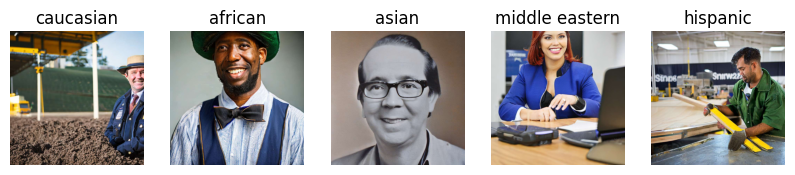

In [6]:
# Insieme per tenere traccia delle etichette già mostrate
shown_labels = set()

# Figura per il plotting
plt.figure(figsize=(10, 10))

# Percorso alla cartella delle immagini
base_path = '/extra/bondielli/_work/diffusion-discrimination/tesi-tosolini/'

# Plotting della prima immagine di ogni etichetta
for i, sample in enumerate(train_ds):
    image_path = os.path.join(base_path, sample['Path']).replace('\\', '/')
    label = sample['Ethnicity']
    if label not in shown_labels:
        if os.path.exists(image_path):
            img = mpimg.imread(image_path)
            plt.subplot(1, len(train_ds.unique('Ethnicity')), len(shown_labels) + 1)
            plt.imshow(img)
            plt.title(label)
            plt.axis('off')
            shown_labels.add(label)
            if len(shown_labels) == len(train_ds.unique('Ethnicity')):
                break
        else:
            print(f"File non trovato: {image_path}")

plt.show()

# Fine-tuning del modello

Viene implementato il processo di addestramento del modello utilizzando la libreria PyTorch:
*  **definizione di una classe *CustomImageDataset*:** gestisce il caricamento delle immagini da un dataframe e le loro etichette associate. La classe viene sfruttata per creare due oggetti: uno per il training e uno per la validazione.
*  **configurazione dell'ambiente di lavoro per il *fine-tuning*:** si verifica se è disponibile una GPU, altrimenti si utilizza la CPU. Viene caricato il modello pre-addestrato ResNet e il relativo processore. La funzione di perdita utilizzata è la *Cross Entropy* e viene scelto l'ottimizzatore *Adam* con un termine di regolarizzazione L2 (*weight decay*) per prevenire l'*overfitting*.
*  **definizione del ciclo di addestramento:** durante ogni epoca, il modello viene impostato in modalità di addestramento e si calcola la perdita su ogni batch. Dopo aver aggiornato i pesi del modello attraverso la *backpropagation*, viene stampata la perdita totale per ogni batch. Alla fine di ogni epoca, si calcola anche la perdita media.
*  **valutazione sul validation set:** il modello viene valutato su un dataset di validazione per monitorarne le prestazioni mentre viene addestrato. Si calcolano la perdita e l'accuratezza (durante questa fase, non vengono calcolati i gradienti per risparmiare risorse). È stata implementata una logica di *early stopping* per interrompere l'addestramento se il modello non mostra miglioramenti nella *validation loss* per un certo numero di epoche; in tal caso, viene salvato il miglior modello trovato fino a quel momento.

###Variabili per l'addestramento

In [7]:
# Creazione del dataset
class CustomImageDataset(torch.utils.data.Dataset):
    # Inizializza il dataset con il dataframe, il percorso base delle immagini e un dizionario di etichette
    def __init__(self, dataset, base_path, label2id=None):
        self.dataset = dataset
        self.base_path = base_path
        self.label2id = label2id
    # Restituisce il numero di immagini nel dataset
    def __len__(self):
        return len(self.dataset)
    # Restituisce l'immagine e la sua etichetta come tensore
    def __getitem__(self, idx):
        img_path = os.path.join(self.base_path, self.dataset[idx]['Path']).replace('\\', '/')
        image = mpimg.imread(img_path)
        image = image.astype(np.float32) / 255.0
        label = self.label2id[self.dataset[idx]['Ethnicity']]
        return image, torch.tensor(label, dtype=torch.long)

# Dropout
class CustomResNetModel(ResNetForImageClassification):
    def __init__(self, *args, dropout_rate, **kwargs):
        super().__init__(*args, **kwargs)
        self.dropout = nn.Dropout(p=dropout_rate)

    def forward(self, **kwargs):
        outputs = super().forward(**kwargs)
        logits = outputs.logits
        logits = self.dropout(logits)
        outputs.logits = logits

        return outputs

# Dizionario delle label
id2label = {id: label for id, label in enumerate(train_ds.unique('Ethnicity'))}
label2id = {label: id for id, label in id2label.items()}

# Imposta il dispositivo: verifica se una GPU è disponibile, altrimenti utilizza la CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Parametri di addestramento
model_save_path = 'resnet-50-ethnicity-1ex/'
num_epochs = 40
batch_size = 32
learning_rate = 2e-4
weight_decay = 0.005
dropout_rate = 0.3
early_stopping_patience = 7

# Creazione dei DataLoader
custom_train_dataset = CustomImageDataset(train_ds, base_path, label2id=label2id)
custom_val_dataset = CustomImageDataset(val_ds, base_path, label2id=label2id)
train_loader = DataLoader(custom_train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(custom_val_dataset, batch_size=batch_size, shuffle=False)

# Modello e processore
processor = AutoImageProcessor.from_pretrained("microsoft/resnet-50")
model = CustomResNetModel.from_pretrained("microsoft/resnet-50", dropout_rate=dropout_rate)
model = model.to(device)

# Funzione di perdita e ottimizzatore
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

# Inizializzazione del ciclo di addestramento
best_val_loss = float('inf')
patience_counter = 0
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3, verbose=True)

In [8]:
# Ciclo di addestramento
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for batch_idx, (images, labels) in enumerate(train_loader):
        images, labels = images.to(device), labels.to(device)
        inputs = processor(images, return_tensors="pt", do_rescale=False).to(device)
        optimizer.zero_grad()
        outputs = model(**inputs).logits
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        # Salva il modello per ogni epoca
        #torch.save(model.state_dict(), model_save_path + 'model_epoch_{}.pth'.format(epoch))
        # Stampa la perdita per ogni batch
        print(f'Epoch [{epoch + 1}/{num_epochs}], Batch [{batch_idx + 1}/{len(train_loader)}], Batch Loss: {loss.item():.4f}')

    # Stampa la perdita media per l'epoca
    print(f'Epoch [{epoch + 1}/{num_epochs}], Average Loss: {running_loss / len(train_loader):.4f}')

    # Valutazione sul validation set
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():  # Disabilita il calcolo dei gradienti
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            inputs = processor(images, return_tensors="pt", do_rescale=False).to(device)
            outputs = model(**inputs).logits
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    # Calcola e stampa la perdita e l'accuratezza sul validation set
    val_loss_avg = val_loss / len(val_loader)
    val_accuracy = correct / total
    print(f'Validation Loss: {val_loss_avg:.4f}, Validation Accuracy: {val_accuracy:.4f}')

    # Controllo dell'early stopping e salvataggio del miglior modello
    if val_loss_avg < best_val_loss:
        best_val_loss = val_loss_avg
        patience_counter = 0
        torch.save(model.state_dict(), model_save_path + 'best_model.pth')
    else:
        patience_counter += 1

    scheduler.step(val_loss_avg)

    if patience_counter >= early_stopping_patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

print("Training completed.")

Epoch [1/40], Batch [1/147], Batch Loss: 17.4866
Epoch [1/40], Batch [2/147], Batch Loss: 13.9607
Epoch [1/40], Batch [3/147], Batch Loss: 15.6939
Epoch [1/40], Batch [4/147], Batch Loss: 15.4131
Epoch [1/40], Batch [5/147], Batch Loss: 12.7953
Epoch [1/40], Batch [6/147], Batch Loss: 15.2111
Epoch [1/40], Batch [7/147], Batch Loss: 13.0609
Epoch [1/40], Batch [8/147], Batch Loss: 13.0191
Epoch [1/40], Batch [9/147], Batch Loss: 13.8233
Epoch [1/40], Batch [10/147], Batch Loss: 14.4374
Epoch [1/40], Batch [11/147], Batch Loss: 12.8549
Epoch [1/40], Batch [12/147], Batch Loss: 13.8133
Epoch [1/40], Batch [13/147], Batch Loss: 14.8709
Epoch [1/40], Batch [14/147], Batch Loss: 13.2703
Epoch [1/40], Batch [15/147], Batch Loss: 12.3102
Epoch [1/40], Batch [16/147], Batch Loss: 13.8793
Epoch [1/40], Batch [17/147], Batch Loss: 11.7881
Epoch [1/40], Batch [18/147], Batch Loss: 13.0083
Epoch [1/40], Batch [19/147], Batch Loss: 11.1444
Epoch [1/40], Batch [20/147], Batch Loss: 12.5748
Epoch [1/

### Valutazione delle prestazioni

*  **creazione di un dataset per il test set** utilizzando la classe *CustomImageDataset*, con i dati provenienti da *test_ds* e le mappature di etichette da *label2id*. Viene impostato un DataLoader per gestire il caricamento delle immagini in batch (32 immagini per volta, senza mescolamento dei dati).
*  **definizione della funzione *plot_confusion_matrix***, che crea una rappresentazione grafica della matrice, evidenziando le true label e le label previste dal modello.
*  **definizione del ciclo di valutazione sul test set:** dopo aver impostato il modello in modalità di valutazione disabilitando il calcolo dei gradienti, le predizioni vengono memorizzate in una lista insieme alle true label.
*  **salvataggio dei risultati in un file di output:** dopo aver creato un DataFrame contenente le true label, le label previste e i percorsi delle immagini, i risultati vengono salvati nel file *ethn_classifier_predictions.csv*.
*  **filtraggio delle predizioni fuori range** e **ricalcolo della matrice di confusione**
*  **stampa del report di classificazione** tramite la funzione *classification_report*, che fornisce metriche sulle performance del modello (*precision*, *recall* e *f1-score*) per ciascuna etnia.

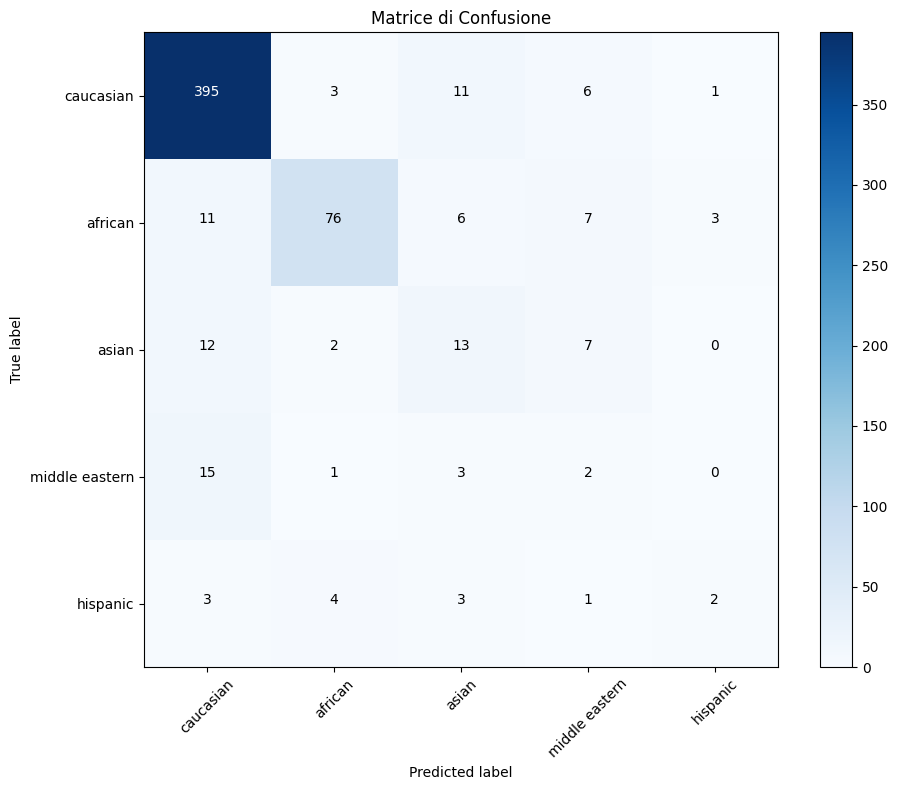

                precision    recall  f1-score   support

     caucasian       0.91      0.95      0.93       416
       african       0.88      0.74      0.80       103
         asian       0.36      0.38      0.37        34
middle eastern       0.09      0.10      0.09        21
      hispanic       0.33      0.15      0.21        13

      accuracy                           0.83       587
     macro avg       0.51      0.46      0.48       587
  weighted avg       0.83      0.83      0.83       587



In [9]:
# Test set
custom_test_dataset = CustomImageDataset(test_ds, base_path, label2id=label2id)
test_loader = DataLoader(custom_test_dataset, batch_size=32, shuffle=False)

# Funzione per calcolare e visualizzare la matrice di confusione
def plot_confusion_matrix(y_true, y_pred, classes):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Matrice di Confusione')
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    thresh = cm.max() / 2
    for i, j in np.ndindex(cm.shape):
        plt.text(j, i, cm[i, j], horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()

# Valutazione delle performance del modello sul test set
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        inputs = processor(images, return_tensors="pt", do_rescale=False).to(device)
        outputs = model(**inputs).logits
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# DataFrame con i risultati
results_df = pd.DataFrame({
    'True Label': all_labels,
    'Predicted Label': all_preds
})
results_df['Path'] = [os.path.join(base_path, test_ds[i]['Path']).replace('\\', '/') for i in range(len(test_ds))]
results_df.to_csv('ethn_classifier_predictions-1ex.csv', index=False)

# Filtra le predizioni fuori range
valid_indices = [i for i, pred in enumerate(all_preds) if pred in np.unique(all_labels)]
all_preds_filtered = [all_preds[i] for i in valid_indices]
all_labels_filtered = [all_labels[i] for i in valid_indices]

# Ricalcola la matrice di confusione e il report di classificazione
plot_confusion_matrix(all_labels_filtered, all_preds_filtered, classes=list(label2id.keys()))
print(classification_report(all_labels_filtered, all_preds_filtered, target_names=list(label2id.keys())))